# #30DayMapChallenge — Day 10: clustering the embeddings

The first notebook (`gdsl30dmc.ipynb`) found the UK's most dissimilar neighbouring small areas, but the top results were nearly always built-up land against open land. Here we cluster the 2024 AlphaEarth embeddings into groups of similar areas, interpret the groups visually, and then search for contrasts between *types* of place, e.g. the industrial estate next to the most different landscape. Shared data loading, contiguity and Polaroid cards come from `gdsl30dmc_tools.py`.


## Setup

Libraries for this notebook: `scikit-learn` for k-means and silhouette scores, plus the shared `gdsl30dmc_tools` module. `autoreload` picks up edits to the module without restarting the kernel.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import gdsl30dmc_tools as tools

## Reading data

We load the 2024 areas and build the same neighbour graph as in the first notebook: fuzzy contiguity, which is queen contiguity plus the overlapping England–Scotland border pairs. We drop the 12 island areas with no neighbours. Each embedding vector is scaled to length 1, so that k-means, which works with Euclidean distance, effectively groups areas by cosine similarity, the same measure used in the first notebook.

In [2]:
%%time
YEAR = 2024
lsoas = tools.load_areas(YEAR)
g = tools.contiguity(lsoas)
lsoas, g = tools.drop_isolates(lsoas, g)

emb = np.ascontiguousarray(lsoas[tools.band_columns(lsoas)].to_numpy())
emb_unit = emb / np.linalg.norm(emb, axis=1, keepdims=True)
uk_outline = tools.uk_outline(lsoas)

print(f"{len(lsoas):,} areas | {g.n_edges:,} links | embeddings {emb_unit.shape}")

46,832 areas | 272,466 links | embeddings (46832, 64)
CPU times: user 5.81 s, sys: 165 ms, total: 5.98 s
Wall time: 5.99 s


## Choosing the number of clusters

Before fixing k, we fit k-means for a range of values and record two things: the silhouette score (how well separated the clusters are, from −1 to 1, computed with cosine distance on a 10,000-area sample) and the size of the smallest cluster. There's no single right k here: the aim is a number of groups we can label by eye that still keeps rare land types visible.

In [3]:
%%time
KS = [5, 8, 10, 15, 20, 25, 30, 40, 50, 75, 100]
sample = np.random.default_rng(0).choice(len(emb_unit), 10_000, replace=False)

rows = []
for k in KS:
    labels = KMeans(k, n_init=3, random_state=0).fit_predict(emb_unit)
    sizes = np.bincount(labels)
    rows.append({"k": k, "silhouette": silhouette_score(emb_unit[sample], labels[sample], metric="cosine"),
                 "smallest": sizes.min(), "largest": sizes.max()})
k_scan = pd.DataFrame(rows).set_index("k")
k_scan.round(3)

CPU times: user 3min 37s, sys: 1min 3s, total: 4min 41s
Wall time: 52.5 s


,silhouette,smallest,largest
k,,,
5,0.287,5459,13471
8,0.269,3459,9432
10,0.244,2562,7845
15,0.225,1544,5494
20,0.212,842,3634
25,0.211,669,3258
30,0.190,514,2534
40,0.181,282,2084
50,0.173,195,1684


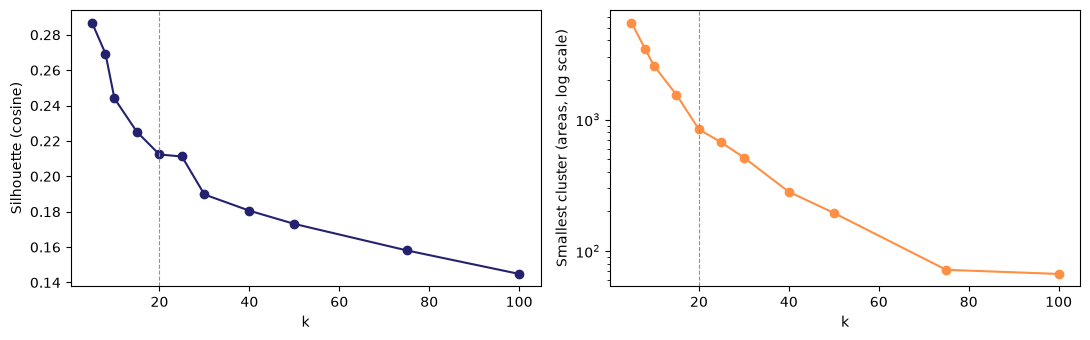

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
k_scan["silhouette"].plot(ax=ax1, marker="o", color=tools.IMAGO["navy"])
ax1.set_ylabel("Silhouette (cosine)")
k_scan["smallest"].plot(ax=ax2, marker="o", color=tools.IMAGO["orange"], logy=True)
ax2.set_ylabel("Smallest cluster (areas, log scale)")
for ax in (ax1, ax2):
    ax.axvline(20, color=tools.IMAGO["dark_grey"], ls="--", lw=0.8)
    ax.set_xlabel("k")
fig.tight_layout()

Silhouette falls steadily as k grows, with no peak or elbow: the embeddings form continuous gradients (rural → suburban → dense urban) rather than separate clumps, so any k slices a continuum. The smallest cluster shrinks steadily too, then drops sharply between k=50 (195 areas) and k=75 (72 areas). That is likely where rare land types (water, airports, quarries) split off. An earlier scratch run, which included the 12 island areas, put this drop between k=40 and k=50, so its exact position is somewhat sensitive. We use **k=20** to label the main groups (190 possible pairs of cluster types, every cluster with at least ~840 areas) and also record a finer level to keep the rare types visible.


## Clustering the embeddings

We fit k-means at two levels: **k=20** for the main land types we'll label by eye, and **k=100** for a finer split that should separate rarer types. We use 10 random starts per fit for stability, and number the clusters in each level by size (0 = largest), so the numbering stays meaningful. The labels are saved to `data/clusters_2024.parquet` for reuse.

In [5]:
%%time
def fit_kmeans(k, seed=0):
    km = KMeans(k, n_init=10, random_state=seed).fit(emb_unit)
    order = np.argsort(-np.bincount(km.labels_))  # old label of the largest cluster first
    relabel = np.empty(k, int)
    relabel[order] = np.arange(k)
    return relabel[km.labels_], km.cluster_centers_[order]

c20, centres20 = fit_kmeans(20)
c100, centres100 = fit_kmeans(100)
clusters = pd.DataFrame({"c20": c20, "c100": c100}, index=lsoas.index)
clusters.to_parquet(tools.DATA_DIR / f"clusters_{YEAR}.parquet")

print("k=20 sizes:", np.bincount(c20).tolist())
print("k=100 sizes: min", np.bincount(c100).min(), "| median", int(np.median(np.bincount(c100))), "| max", np.bincount(c100).max())

k=20 sizes: [3628, 3338, 3102, 2962, 2856, 2838, 2753, 2738, 2737, 2437, 2354, 2232, 2150, 2070, 2051, 1774, 1461, 1334, 1180, 837]
k=100 sizes: min 71 | median 465 | max 869
CPU times: user 2min 23s, sys: 308 ms, total: 2min 23s
Wall time: 13.1 s


### How the two levels nest

k-means fits the two levels independently, so a fine cluster need not sit inside a single coarse one. For each k=100 cluster, we record which k=20 cluster most of its areas belong to and how large that share is. High shares mean the fine level mostly subdivides the coarse one, which makes the two levels easier to read together.

In [6]:
nest = pd.crosstab(clusters.c100, clusters.c20)
fine = pd.DataFrame({
    "size": nest.sum(axis=1),
    "main_c20": nest.idxmax(axis=1),
    "share": (nest.max(axis=1) / nest.sum(axis=1)).round(2),
})
print("Share of each k=100 cluster inside its main k=20 cluster:")
print(fine["share"].describe().round(2).to_string())
print("\nk=100 clusters per k=20 cluster:")
print(fine.groupby("main_c20").size().to_string())

Share of each k=100 cluster inside its main k=20 cluster:
count    100.00
mean       0.67
std        0.22
min        0.21
25%        0.50
50%        0.61
75%        0.86
max        1.00

k=100 clusters per k=20 cluster:
main_c20
0     7
1     8
2     4
3     6
4     6
5     8
6     4
7     5
8     5
9     5
10    6
11    3
12    5
13    3
14    4
15    4
16    4
17    5
18    3
19    5


## What the clusters look like

To interpret each k=20 cluster, we look at its six most typical areas: those whose embedding is closest (highest cosine similarity) to the cluster centre. Each is shown as a satellite thumbnail with the area outlined and its surroundings washed out. The sheets are saved to `figures/clusters/` so we can review them side by side and agree labels.

In [7]:
def typical(level_labels, centres, cluster, n=6):
    """Codes of the n areas in `cluster` closest to its centre (cosine similarity)."""
    members = np.flatnonzero(level_labels == cluster)
    centre = centres[cluster] / np.linalg.norm(centres[cluster])
    best = members[np.argsort(-(emb_unit[members] @ centre))[:n]]
    return lsoas.index[best].tolist()

typical20 = {c: typical(c20, centres20, c) for c in range(20)}

In [8]:
%%time
sheet_dir = tools.FIG_DIR / "clusters"
for c, codes in typical20.items():
    fig = tools.contact_sheet(lsoas, codes, f"k=20 cluster {c} · {np.sum(c20 == c):,} areas")
    tools.export_card(fig, f"c20_{c:02d}", dpi=110, fig_dir=sheet_dir)
    plt.close(fig)
sorted(p.name for p in sheet_dir.glob("c20_*.png"))[:3]

CPU times: user 1min 13s, sys: 49.6 s, total: 2min 2s
Wall time: 3min 23s


['c20_00.png', 'c20_01.png', 'c20_02.png']

### Clusters by nation

Some contact sheets show areas from a single nation only (e.g. all Scottish codes). The table below gives the share of each cluster's areas in each nation, alongside the cluster's median area size, so we can see which clusters are tied to one nation.

In [9]:
by_nation = pd.crosstab(clusters.c20, tools.nation(lsoas), normalize="index").round(2)
by_nation["median_km2"] = (lsoas.area / 1e6).groupby(clusters.c20).median().round(2)
by_nation

data_zone_code,E,N,S,W,median_km2
c20,,,,,
0,0.87,0.01,0.02,0.09,0.41
1,0.10,0.29,0.60,0.00,0.15
2,0.99,0.00,0.00,0.01,0.33
3,0.97,0.00,0.00,0.03,0.68
4,0.97,0.00,0.00,0.03,0.32
5,0.08,0.19,0.71,0.01,0.29
6,0.99,0.00,0.00,0.01,0.36
7,0.97,0.00,0.00,0.03,0.26
8,0.95,0.00,0.05,0.00,12.95


## Business cores (k=100 cluster 95)

The k=20 cluster we first read as "city centres" (cluster 18) turned out broader: dense inner-city mixed use, with flats, offices and institutions. To find true city centres we look at the k=100 level instead. Areas in the City of London and central Manchester fall into k=100 clusters 95 and 88. The contact sheets show that **cluster 95** is the high-rise office district: towers, big flat roofs and almost no green space. Cluster 88 is central mixed use, so we focus on 95 and call it the **business core** cluster.

In [10]:
known = ["E01000001", "E01000002", "E01000003", "E01000005", "E01032739", "E01032740",  # City of London
         "E01033677", "E01033658", "E01033654", "E01033664"]                              # central Manchester
print("k=100 cluster of known central areas:", clusters.loc[known, "c100"].value_counts().to_dict())

core = clusters.index[clusters.c100 == 95]
print(f"Cluster 95: {len(core)} areas | median {lsoas.area[core].median() / 1e6:.2f} km² | "
      f"{tools.nation(lsoas.loc[core]).value_counts().to_dict()} | "
      f"{(clusters.c20[core] == 18).mean():.0%} in k=20 cluster 18")

k=100 cluster of known central areas: {95: 6, 88: 4}
Cluster 95: 133 areas | median 0.11 km² | {'E': 114, 'S': 17, 'N': 2} | 65% in k=20 cluster 18


CPU times: user 4.99 s, sys: 7.43 s, total: 12.4 s
Wall time: 15.4 s


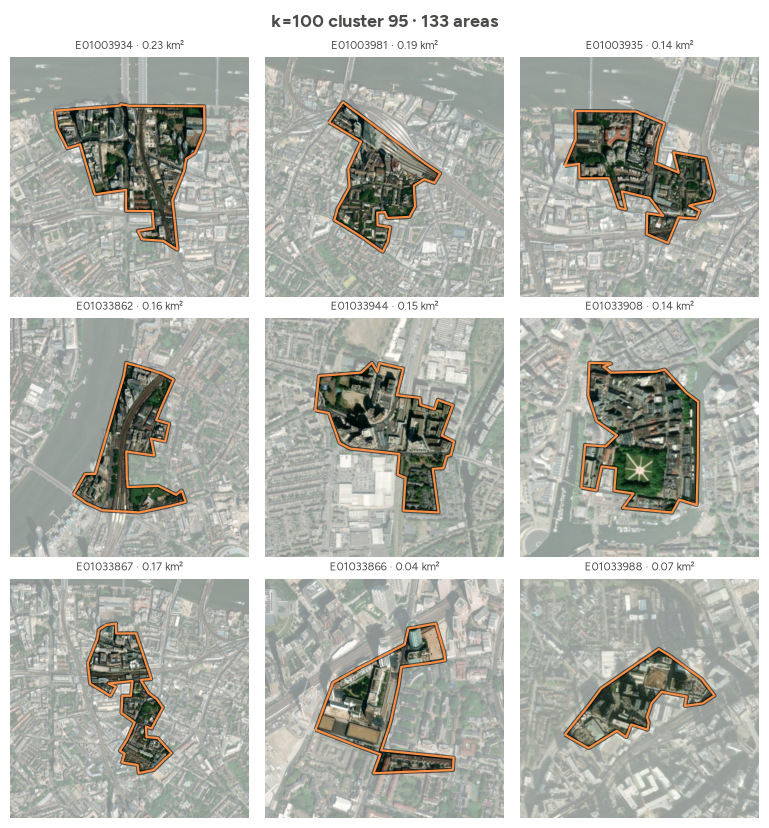

In [11]:
%%time
fig = tools.contact_sheet(lsoas, typical(c100, centres100, 95, n=9), f"k=100 cluster 95 · {len(core)} areas")
tools.export_card(fig, "c100_95", dpi=110, fig_dir=sheet_dir);

### Business cores next to their most different neighbours

We take the cosine distance of every neighbouring pair (computed once and cached by `tools.pair_distances`) and keep the pairs that include a business-core area, with the core area listed first. As in the first notebook, we pick the top pairs greedily, skipping any pair that shares an area with one already chosen. The neighbour's k=20 and k=100 clusters show what kind of place the core sits against.

In [12]:
pair_dist = tools.pair_distances(lsoas, g)
assert len(pair_dist) == g.n_edges // 2

core_pairs = pair_dist.reset_index()
in_a, in_b = core_pairs.a.isin(core), core_pairs.b.isin(core)
core_pairs = core_pairs[in_a | in_b]
swap = ~in_a[core_pairs.index]  # put the core area first
core_pairs.loc[swap, ["a", "b"]] = core_pairs.loc[swap, ["b", "a"]].to_numpy()
core_pairs = core_pairs.sort_values("dist", ascending=False)

used, picks = set(), []
for row in core_pairs.itertuples():
    if row.a in used or row.b in used:
        continue
    picks.append(row)
    used |= {row.a, row.b}
    if len(picks) == 5:
        break
top_core_pairs = pd.DataFrame(picks).drop(columns="Index").assign(
    nbr_c20=lambda d: clusters.c20[d.b].to_numpy(), nbr_c100=lambda d: clusters.c100[d.b].to_numpy(),
    rank=lambda d: [f"top {(pair_dist >= x).mean():.2%}" for x in d.dist])
print(f"{len(core_pairs):,} neighbouring pairs include a business-core area")
top_core_pairs.round(3)

563 neighbouring pairs include a business-core area


,a,b,dist,nbr_c20,nbr_c100,rank
0,E01035620,E01035617,0.408,14,47,top 0.03%
1,E01034486,E01004401,0.289,0,99,top 0.60%
2,S01017417,S01017432,0.268,15,61,top 0.97%
3,S01017414,S01017176,0.257,5,32,top 1.26%
4,S01017427,S01017433,0.254,15,61,top 1.32%


Each pair becomes a Polaroid card with the core area in orange. In place of the distance histogram, the caption strip shows the two embeddings band by band (`emb_style="shared"`): where both areas lean the same way, the part they share is grey and only the excess is coloured; bands where they point in opposite directions are fully orange and green. The more grey, the more alike the two areas are. Cards are saved to `figures/core/`.

CPU times: user 6.49 s, sys: 4.45 s, total: 10.9 s
Wall time: 13.7 s


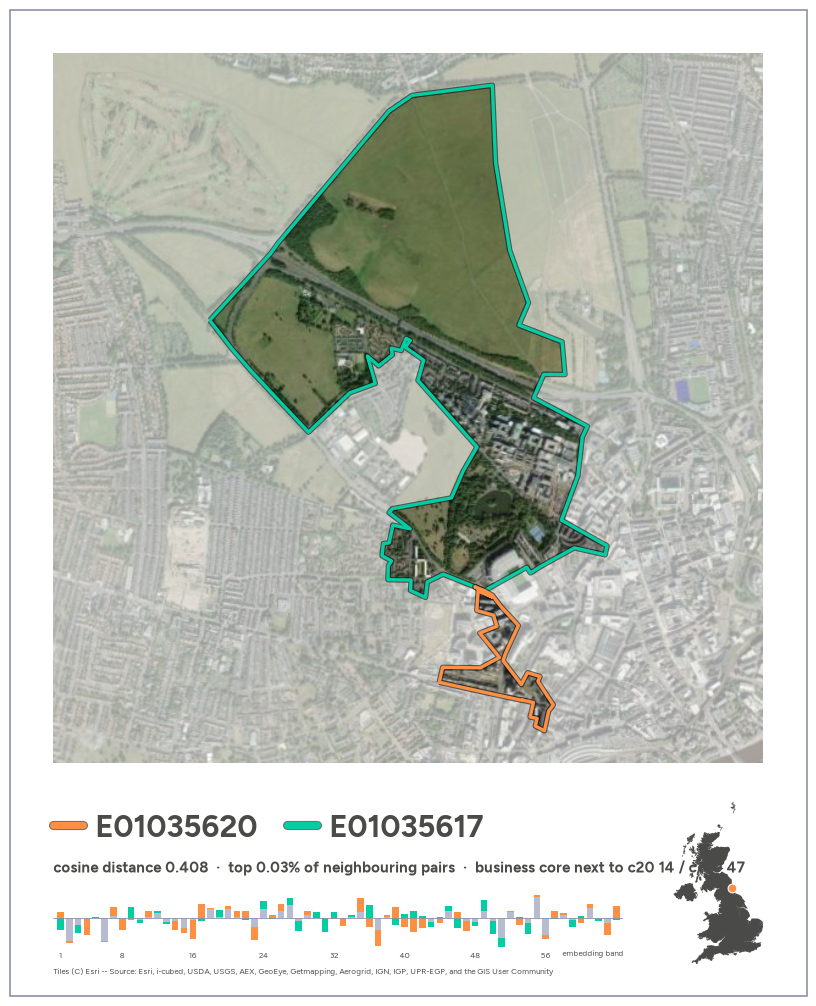

In [13]:
%%time
bands = lsoas[tools.band_columns(lsoas)]
core_dir = tools.FIG_DIR / "core"
for i, r in enumerate(top_core_pairs.itertuples(), 1):
    subtitle = (f"cosine distance {r.dist:.3f}  ·  {r.rank} of neighbouring pairs  ·  "
                f"business core next to c20 {r.nbr_c20} / c100 {r.nbr_c100}")
    fig = tools.pair_card(lsoas, r.a, r.b, subtitle, uk_outline, emb=(bands.loc[r.a], bands.loc[r.b]))
    tools.export_card(fig, f"pair_{i}_{r.a}_{r.b}", fig_dir=core_dir)
    if i > 1:
        plt.close(fig)  # show only the first card inline

All five pairs are in the top 1.5% of the 136,233 neighbouring pairs, but only three make good pictures:

- **1:** fields and a campus.
- **2:** a reservoir and industrial sheds.
- **4:** a riverside park.

Pairs 3 and 5, both in Glasgow, look alike from above: dense blocks with dark roofs on both sides. The embeddings do separate them. The core areas' most similar areas elsewhere are other business cores, while the neighbours belong to a tenement-housing cluster (c100 61, mostly Victorian terraces at k=20), so the difference is plausibly land use (offices vs flats) more than appearance. But both neighbours are tiny (0.06–0.10 km²) and sit on the edge of their own cluster (furthest 2% from its centre), so their distances are less reliable. Cluster 95 is small (133 areas, 563 pairs), so after the first few pairs the remaining contrasts are subtle. A minimum distance or minimum area would filter these out.

### Business cores against their whole neighbourhood

The same search with `lag_dist`: the cosine distance between a core area and the average of its neighbours, taken from `tools.neighbourhood_distances` (which matches the first notebook). The band chart now compares the area (orange) with its average neighbour (green).

In [14]:
nbhd = tools.neighbourhood_distances(lsoas, g)
top_core_lag = nbhd.loc[core].sort_values("lag_dist", ascending=False).head(5).assign(
    neighbours=lambda d: [g.cardinalities[c] for c in d.index],
    km2=lambda d: lsoas.area[d.index] / 1e6,
    rank=lambda d: [f"top {(nbhd.lag_dist >= x).mean():.2%}" for x in d.lag_dist])
top_core_lag.round(3)

,mean_dist,lag_dist,neighbours,km2,rank
data_zone_code,,,,,
E01034486,0.236,0.180,3,0.086,top 0.29%
S01017173,0.100,0.096,2,0.016,top 2.66%
E01034178,0.089,0.086,2,0.022,top 3.66%
E01033684,0.106,0.084,3,0.045,top 3.86%
E01033874,0.091,0.076,5,0.057,top 5.09%


CPU times: user 8.28 s, sys: 169 ms, total: 8.45 s
Wall time: 10.1 s


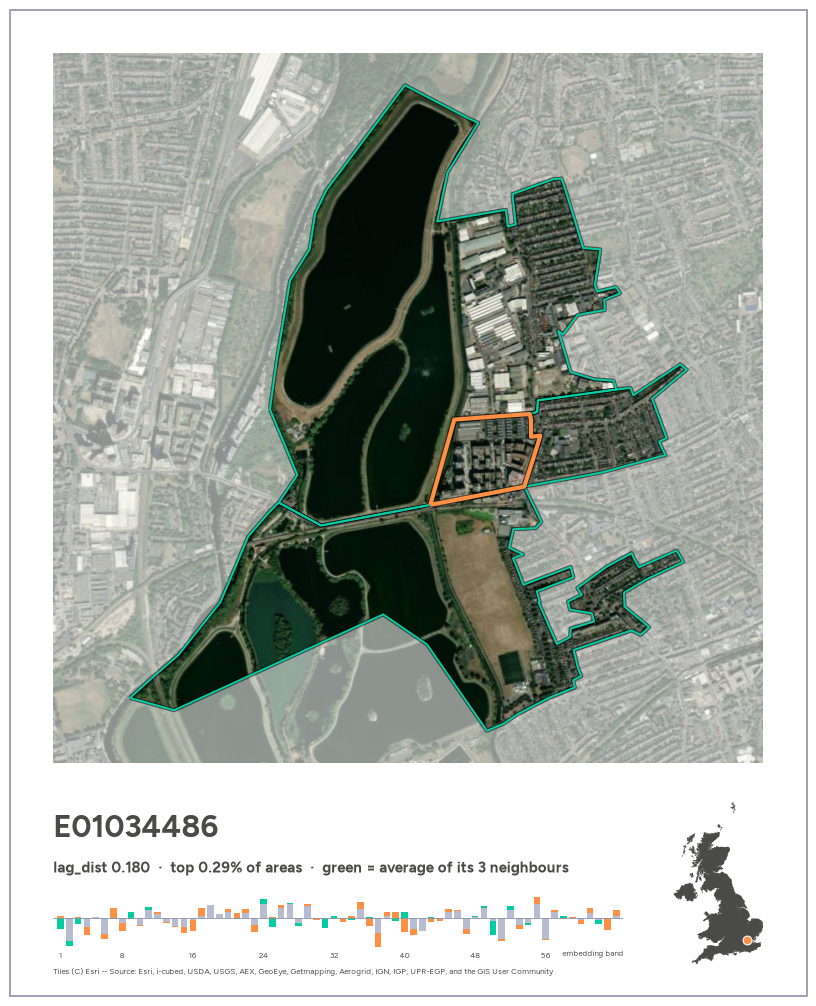

In [15]:
%%time
for i, (code, r) in enumerate(top_core_lag.iterrows(), 1):
    nbrs = g.neighbors[code]
    subtitle = (f"lag_dist {r.lag_dist:.3f}  ·  {r['rank']} of areas  ·  "
                f"green = average of its {r.neighbours} neighbours")
    fig = tools.area_card(lsoas, code, nbrs, subtitle, uk_outline, emb=(bands.loc[code], bands.loc[list(nbrs)].mean()))
    tools.export_card(fig, f"lag_{i}_{code}", fig_dir=core_dir)
    if i > 1:
        plt.close(fig)

Only the first card is a clear outlier: the office and flats block surrounded by reservoirs (top 0.29% of all areas). The rest fall to the top 3–5%, because averaging the neighbours dilutes the contrast: a core with a park on one side and dense blocks on the other looks ordinary against its average neighbour. Most of these areas also have only 2–3 neighbours and some are tiny (about 0.02 km²), the same small-area caveat as the pairs. Visually, though, cards 3–5 (riverside towers, an office block by a stadium, towers around a station) show "towers dropped into a neighbourhood" well.

## Distinct entities at k=100

Scanning contact sheets of all 100 fine clusters (4 typical areas each, then 9 for the candidates), most clusters are shades of housing, farmland or fringe. A handful are clearly delimited kinds of place. The labels below are a visual reading of satellite thumbnails, not ground truth. Several types we hoped for (airports, quarries, campuses, cemeteries, stand-alone docks) do not separate at k=100: they are probably smaller than a typical area and get averaged away.

In [16]:
ENTITIES = {
    99: "reservoirs and inland water",
    81: "industrial and transport land",
    50: "industrial and retail parks",
    42: "golf courses and leafy suburbs",
    91: "woodland and heathland",
    90: "harbour and marina waterfront",
    87: "port and coastal industrial towns",
    93: "coastal fringe",
    95: "business cores",
    88: "central mixed use",
}
LANDSCAPES = {97: "Highland mountains and lochs", 98: "Scottish islands and sea lochs", 94: "Scottish uplands",
              85: "English and Welsh uplands", 92: "Welsh valleys"}

entities = pd.DataFrame([
    {"c100": k, "label": v, "areas": int((c100 == k).sum()),
     "median_km2": round(lsoas.area[c100 == k].median() / 1e6, 2),
     **tools.nation(lsoas[c100 == k]).value_counts(normalize=True).round(2).to_dict()}
    for k, v in {**ENTITIES, **LANDSCAPES}.items()
]).set_index("c100").fillna(0)
entities

,label,areas,median_km2,E,N,W,S
c100,,,,,,,
99,reservoirs and inland water,71,1.13,0.65,0.23,0.08,0.04
81,industrial and transport land,320,0.50,0.83,0.05,0.08,0.04
50,industrial and retail parks,464,0.83,0.97,0.00,0.02,0.00
42,golf courses and leafy suburbs,481,1.37,1.00,0.00,0.00,0.00
91,woodland and heathland,184,4.46,0.99,0.00,0.01,0.00
90,harbour and marina waterfront,199,0.52,0.92,0.00,0.08,0.00
87,port and coastal industrial towns,244,0.34,0.23,0.14,0.05,0.58
93,coastal fringe,174,0.92,0.44,0.18,0.08,0.29
95,business cores,133,0.11,0.86,0.02,0.00,0.13


### Most dissimilar neighbours of each entity

For each entity (except business cores, covered above), the top 3 distinct neighbouring pairs that include one of its areas, with the entity area first. To avoid the small-area noise seen in Glasgow, both areas must cover at least 0.05 km². The rank is among all 136,233 neighbouring pairs. Cards are saved to `figures/entities/`.

In [17]:
MIN_KM2 = 0.05
km2 = lsoas.area / 1e6
pair_rank = lambda d: int((pair_dist > d).sum()) + 1

def top_pairs(members, n=3, min_km2=MIN_KM2):
    """Top n distinct neighbouring pairs that include an area in `members`, member first, both areas >= min_km2."""
    p = pair_dist.reset_index()
    in_a, in_b = p.a.isin(members), p.b.isin(members)
    p = p[in_a | in_b]
    swap = ~in_a[p.index]
    p.loc[swap, ["a", "b"]] = p.loc[swap, ["b", "a"]].to_numpy()
    p = p[(km2[p.a].to_numpy() >= min_km2) & (km2[p.b].to_numpy() >= min_km2)].sort_values("dist", ascending=False)
    used, picks = set(), []
    for row in p.itertuples():
        if row.a in used or row.b in used:
            continue
        picks.append(row)
        used |= {row.a, row.b}
        if len(picks) == n:
            break
    return pd.DataFrame(picks).drop(columns="Index")

entity_pairs = pd.concat({
    k: top_pairs(set(clusters.index[clusters.c100 == k])) for k in ENTITIES if k != 95
}, names=["c100", "i"]).reset_index()
entity_pairs["i"] += 1
entity_pairs["rank"] = entity_pairs.dist.map(pair_rank)
entity_pairs["nbr_c100"] = clusters.c100[entity_pairs.b].to_numpy()
entity_pairs.round(3)

,c100,i,a,b,dist,rank,nbr_c100
0,99,1,E01030745,E01030710,0.538,1,5
1,99,2,W01002024,W01001947,0.481,10,50
2,99,3,E01018058,E01018072,0.447,22,56
3,81,1,E01017305,E01017329,0.408,42,31
4,81,2,E01019139,E01019178,0.360,146,36
5,81,3,N20000267,N20000262,0.355,164,0
6,50,1,W01001947,W01002024,0.481,10,99
7,50,2,E01018631,E01018669,0.376,102,74
8,50,3,E01024892,E01024860,0.357,160,74
9,42,1,E01017832,E01016485,0.385,73,69


In [18]:
%%time
entity_dir = tools.FIG_DIR / "entities"
for r in entity_pairs.itertuples():
    subtitle = f"{ENTITIES[r.c100]}  ·  distance {r.dist:.3f}  ·  #{r.rank:,} of {len(pair_dist):,} pairs"
    fig = tools.pair_card(lsoas, r.a, r.b, subtitle, uk_outline, emb=(bands.loc[r.a], bands.loc[r.b]))
    tools.export_card(fig, f"c{r.c100}_{r.i}_{r.a}_{r.b}", fig_dir=entity_dir)
    plt.close(fig)
len(list(entity_dir.glob("*.png")))

CPU times: user 33.2 s, sys: 1.01 s, total: 34.3 s
Wall time: 42.9 s


27

Highlights:

- **Reservoirs #1** is the Staines reservoirs pair, the most dissimilar in the UK.
- **Reservoirs #3** looks like ordinary fenland fields but sits in the water cluster. It is on the Nene Washes, a flood-storage washland that is likely under water for much of the winter, which a single photo cannot show but a year-long embedding can.
- **Industrial and retail parks #2** is a retail park on the edge of Macclesfield set against Peak District moorland.
- **Central mixed use** pairs (central London blocks next to the royal parks) look striking even though their distances are lower.

Caveats:

- The same pair can appear under two entities (open water next to a business park in Cardiff Bay appears under both 99 and 50).
- Clouds show in a few Esri images.

### A warning: similar-looking housing

Restricting the search to pairs where both areas are under 2 km² keeps it inside towns. Most top pairs there are still housing against urban open space (marshes, commons, forest). One exception, `E01004721`–`E01004722` in west London (distance 0.317, #419), is two areas of dense terraced housing that look alike from above.

Neither is an outlier: each is a typical member of its own k=100 cluster (68 and 69), and those two clusters' centres are 0.299 apart, as far as many housing–woodland pairs. Contact sheets of both clusters show dense terraces either way.

An untested hypothesis is **street orientation**. The two grids run roughly at right angles, and AlphaEarth includes radar (Sentinel-1), whose returns from buildings depend strongly on their orientation relative to the satellite track. Since we can't explain the gap, this pair is not used as a showcase card; it is a candidate follow-up ("what do embeddings actually see?").

## Final submission

The exploration ends here. The final cards (most different, most similar and most similar urban neighbours, captioned with haiku) are built from start to end, independently of this notebook, in `gdsl30dmc_submission.ipynb`.